In [1]:
# Dataset folder (relative to ml/notebooks)
DATASET_PATH = '../../data/demo-1.0.0-42'

# Synthetic data: exploration and outlier analysis

Sentinel generates its own data (see `docs/DATA_PIPELINE.md`). Because we designed both the
fraud patterns and the detectors, the main job of this notebook is to check that the data is
**not too easy**: that fraud overlaps legitimate behaviour, that benign anomalies create
false-positive pressure, and that no single feature gives the answer away.

> Synthetic data only. Nothing here estimates real-world detection performance.

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sentinel_ml.datasets import eda

DATASET = Path(DATASET_PATH)
data = eda.load(DATASET)
t, lab, splits = data.transactions, data.labels, data.splits
df = t.merge(lab, on="external_id").merge(splits, on="external_id")
print(f"{DATASET.name}: {len(t):,} transactions, {t.customer_ref.nunique():,} customers")
print(f"injected fraud {lab.is_fraud_injected.mean():.2%}, labelled {lab.is_fraud_labelled.mean():.2%}")

demo-1.0.0-42: 97,151 transactions, 1,999 customers
injected fraud 0.67%, labelled 0.65%


## Volume and mix

In [3]:
summary = pd.DataFrame({
    "transactions": df.groupby("split").size(),
    "fraud_injected": df.groupby("split").is_fraud_injected.sum(),
})
summary["fraud_pct"] = (100 * summary.fraud_injected / summary.transactions).round(2)
display(summary)
display(df[df.is_fraud_injected].groupby("typology").agg(
    transactions=("external_id", "size"), episodes=("scenario_id", "nunique")))
display(df.benign_scenario.value_counts().rename("benign transactions"))

,transactions,fraud_injected,fraud_pct
split,,,
excluded,52,52,100.00
holdout,9212,57,0.62
test,18637,107,0.57
train,53079,314,0.59
validation,16171,122,0.75


,transactions,episodes
typology,,
account_takeover,81,19
card_testing,105,12
high_risk_category_shift,30,10
impossible_travel,53,18
low_and_slow,251,30
mule_passthrough,64,16
night_drain,68,15


benign_scenario
travel            1828
payday_splurge    1143
big_ticket         162
Name: benign transactions, dtype: int64

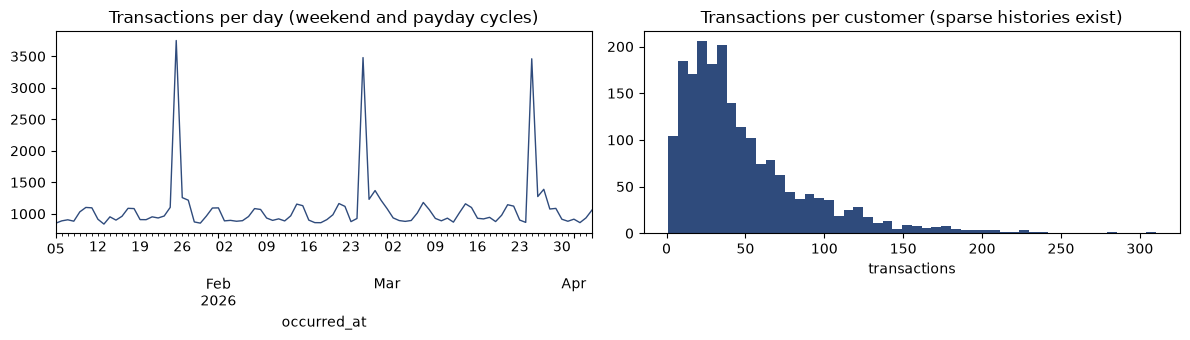

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
daily = df.set_index("occurred_at").resample("D").size()
daily.plot(ax=axes[0], color="#2f4b7c", lw=1)
axes[0].set_title("Transactions per day (weekend and payday cycles)")
per_cust = df.groupby("customer_ref").size()
axes[1].hist(per_cust, bins=50, color="#2f4b7c")
axes[1].set_title("Transactions per customer (sparse histories exist)")
axes[1].set_xlabel("transactions")
plt.tight_layout()

## Amounts by class

Fraud amounts should overlap legitimate ones — injected episodes draw amounts relative to
each customer's own scale, and `low_and_slow` uses ordinary amounts on purpose.

,count,mean,std,min,50%,90%,max
typology,,,,,,,
account_takeover,81.0,4643.0,2263.0,1019.0,4108.0,8007.0,10442.0
card_testing,105.0,788.0,1669.0,1.0,17.0,4645.0,5905.0
high_risk_category_shift,30.0,2708.0,2122.0,607.0,2241.0,4492.0,9056.0
impossible_travel,53.0,4323.0,7873.0,77.0,1287.0,9823.0,46511.0
low_and_slow,251.0,800.0,743.0,38.0,555.0,1624.0,4919.0
mule_passthrough,64.0,14222.0,14790.0,211.0,8300.0,31778.0,59732.0
night_drain,68.0,4375.0,2386.0,1001.0,4056.0,7141.0,12857.0


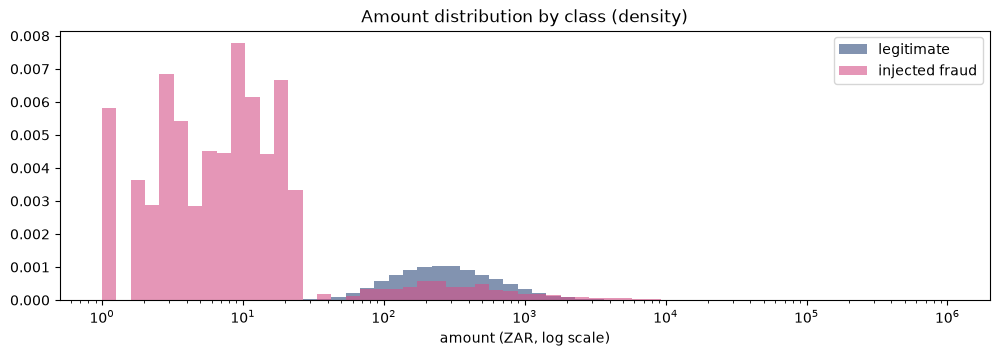

In [5]:
from sentinel.core.vocabulary import FX_TO_ZAR
df["amount_zar"] = df.amount * df.currency.map(FX_TO_ZAR)
fig, ax = plt.subplots(figsize=(12, 3.5))
bins = np.logspace(0, 6, 60)
ax.hist(df.loc[~df.is_fraud_injected, "amount_zar"], bins=bins, density=True, alpha=0.6,
        label="legitimate", color="#2f4b7c")
ax.hist(df.loc[df.is_fraud_injected, "amount_zar"], bins=bins, density=True, alpha=0.6,
        label="injected fraud", color="#d45087")
ax.set_xscale("log"); ax.set_xlabel("amount (ZAR, log scale)"); ax.legend()
ax.set_title("Amount distribution by class (density)")
display(df.groupby("typology").amount_zar.describe(percentiles=[0.5, 0.9]).round(0))

## Outliers: signal or artefact?

Tukey fences (3x IQR on log amount) within each merchant category. The question for each
outlier group is whether it is *signal* (fraud we want to find), *benign* (an anomaly we
generated on purpose, which should not be flagged), or an *artefact* of the generator.

In [6]:
df["amount_outlier"] = eda.amount_outliers(df).to_numpy()
df["kind"] = np.select(
    [df.is_fraud_injected, df.benign_scenario.notna()],
    ["fraud: " + df.typology.fillna(""), "benign: " + df.benign_scenario.fillna("")],
    default="ordinary")
out = df[df.amount_outlier]
print(f"{len(out):,} amount outliers ({len(out)/len(df):.2%} of transactions)")
display(out.kind.value_counts().rename("outliers").to_frame()
        .assign(share=lambda d: (d.outliers / d.outliers.sum()).round(3)))

194 amount outliers (0.20% of transactions)


,outliers,share
kind,,
benign: travel,144,0.742
fraud: card_testing,48,0.247
fraud: impossible_travel,2,0.010


Reading the table: most amount outliers are **not** fraud — benign travel spending
dominates, so a population-level amount rule would mostly flag legitimate activity. The
fraud outliers sit in the *low* tail: card-testing probes of a few rand. High-value fraud
(account takeover, night drain, mule pass-through) stays inside the category fences because
its amounts are drawn relative to each customer's own scale — it is unusual *for that
customer*, not for the population. That is why the features are customer-relative
(`amount_vs_cust_median_90d`) rather than global thresholds.

Outliers are therefore **kept** (they are realistic and informative); heavy-tailed features
are log-transformed, and models that need scaling do it inside the training pipeline
(Phase 6).

## Single-feature leakage check

Each model input on the training split, scored on its own. A feature with separability
≥ 0.95 would suggest the generator left a fingerprint.

In [7]:
X, y = eda.training_matrix(data)
sep = eda.single_feature_auc(X, y)
display(sep.head(12).round(3))
print("suspicious features:", sep.loc[sep.suspicious, "feature"].tolist() or "none")

,feature,auc,separability,suspicious
0,channel_online,0.771,0.771,False
1,channel_card_present,0.269,0.731,False
2,is_new_device_90d,0.723,0.723,False
3,log_secs_since_prev_txn,0.301,0.699,False
4,txn_count_1h,0.656,0.656,False
5,txn_count_24h,0.655,0.655,False
6,log_velocity_ratio_24h_vs_30d,0.647,0.647,False
7,log_spend_sum_24h_zar,0.632,0.632,False
8,high_risk_category,0.619,0.619,False
9,hour_rarity_cust,0.599,0.599,False


suspicious features: none


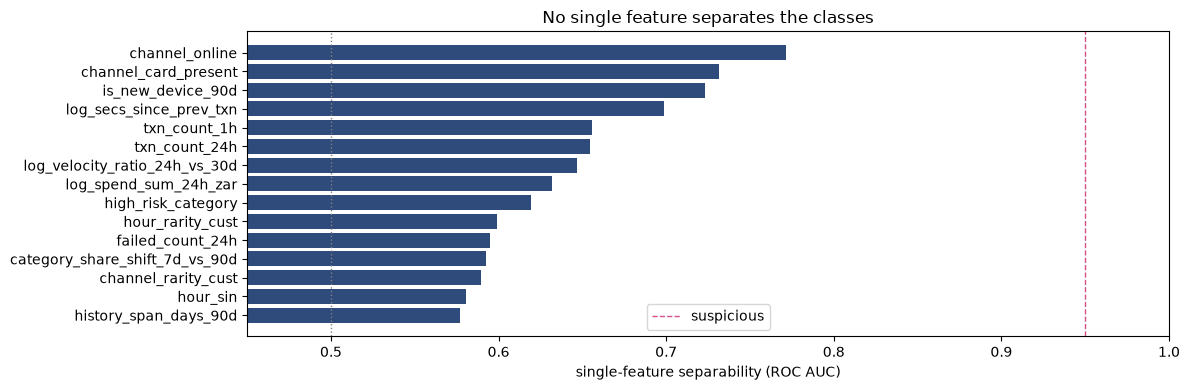

In [8]:
fig, ax = plt.subplots(figsize=(12, 4))
top = sep.head(15)[::-1]
ax.barh(top.feature, top.separability, color="#2f4b7c")
ax.axvline(0.5, color="grey", lw=1, ls=":")
ax.axvline(eda.SUSPICIOUS_AUC, color="#d45087", lw=1, ls="--", label="suspicious")
ax.set_xlim(0.45, 1.0); ax.set_xlabel("single-feature separability (ROC AUC)"); ax.legend()
ax.set_title("No single feature separates the classes")
plt.tight_layout()

## Per-typology difficulty preview

How often does each typology show the behavioural signal its rule looks for? `low_and_slow`
is expected to look ordinary on every feature — the intended false negatives.

In [9]:
f = data.features.merge(lab, on="external_id")
checks = {
    "new device": f.is_new_device_90d == True,  # noqa: E712
    "new city": f.is_new_city_90d == True,  # noqa: E712
    "amount >= 3x median": f.amount_vs_cust_median_90d >= 3,
    "speed >= 900 km/h": f.implied_speed_kmh >= 900,
    "failed in 24h >= 3": f.failed_count_24h >= 3,
    "rare hour (>= 0.97)": f.hour_rarity_cust >= 0.97,
}
rates = pd.DataFrame({name: m.groupby(f.typology.fillna("legitimate")).mean()
                      for name, m in checks.items()})
display((100 * rates).round(1))

,new device,new city,amount >= 3x median,speed >= 900 km/h,failed in 24h >= 3,rare hour (>= 0.97)
typology,,,,,,
account_takeover,16.0,9.9,76.5,0.0,2.5,9.9
card_testing,9.5,0.0,14.3,0.0,42.9,1.0
high_risk_category_shift,0.0,0.0,70.0,0.0,0.0,26.7
impossible_travel,0.0,34.0,47.2,28.3,0.0,13.2
legitimate,3.4,0.7,16.1,0.0,0.0,9.5
low_and_slow,2.0,0.0,4.4,0.0,0.0,26.7
mule_passthrough,1.6,0.0,82.8,0.0,0.0,32.8
night_drain,2.9,0.0,72.1,0.0,0.0,32.4


## Conclusions

- Fraud is ~0.7% of transactions, spread over seven typologies, with a few episodes left
  unlabelled on purpose.
- Fraud and legitimate amounts overlap heavily; most amount outliers are benign travel, and
  the fraud outliers are tiny card-testing probes.
- No single model input is near-perfectly separating (best ≈ 0.77 AUC on the demo
  dataset), so models must combine signals.
- Episode signals are partial by construction: only the first transaction of a takeover is
  on a "new" device, and only the first jump of an impossible-travel episode has an
  implausible speed.
- `low_and_slow` shows almost none of the behavioural signals — expect it to be missed.
- About 16% of legitimate transactions are ≥ 3x the customer's median, so relative-amount
  rules carry real false-positive load.

These properties are re-checked automatically by the tests in `ml/tests/`.